In [ ]:
import zipfile
import io
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import spacy
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/fake_news.zip"

# Download the ZIP file.
dl_zip_file = urllib.request.urlopen(URL)
zip_files = zipfile.ZipFile(io.BytesIO(dl_zip_file.read()))
print("File names:", zip_files.namelist())

# Extract and read each CSV file.
with zip_files.open("Fake.csv") as f:
  fake_df = pd.read_csv(f)

with zip_files.open("True.csv") as t:
  true_df = pd.read_csv(t)

print(f"\n --- FAKE FILE---")
print(f"Fake file rows: {len(fake_df)}")
display(fake_df.head())

print(f"\n --- TRUE FILE---")
print(f"True file rows: {len(true_df)}")
display(true_df.head())

File names: ['Fake.csv', 'True.csv']

 --- FAKE FILE---
Fake file rows: 23481


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



 --- TRUE FILE---
True file rows: 21417


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [ ]:
# Add the "label" column to both DataFrames.
fake_df["label"] = "Fake"
true_df["label"] = "True"

# Concatenate the datasets vertically.
conc_dataset = pd.concat([fake_df, true_df], ignore_index=True)

# Shuffle the dataset so that it can be split into training and test sets for a machine learning model.
new_df = conc_dataset.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Shape of the new combined dataset: {new_df.shape}")
display(new_df[["title", "subject", "label"]].head())


Shape of the new combined dataset: (44898, 5)


,title,subject,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,US_News,Fake
1,Trump drops Steve Bannon from National Securit...,politicsNews,True
2,Puerto Rico expects U.S. to lift Jones Act shi...,politicsNews,True
3,OOPS: Trump Just Accidentally Confirmed He Le...,News,Fake
4,Donald Trump heads for Scotland to reopen a go...,politicsNews,True


In [ ]:
# Data exploration.
new_df.info()

print(f"\nMissing values per column:")
print(new_df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  object
dtypes: object(5)
memory usage: 1.7+ MB

Missing values per column:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


--- NEWS DISTRIBUTION ---


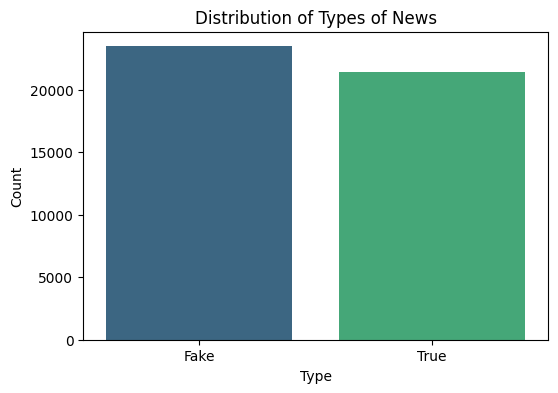

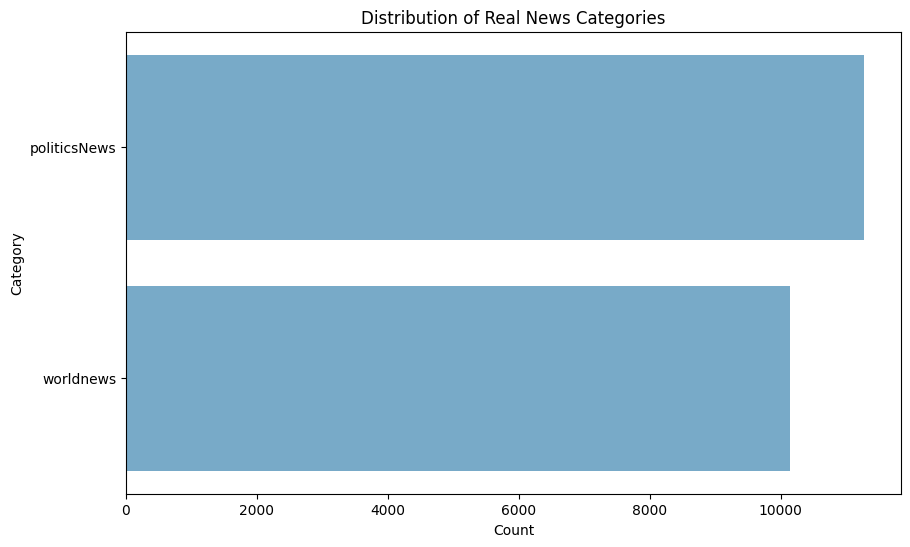

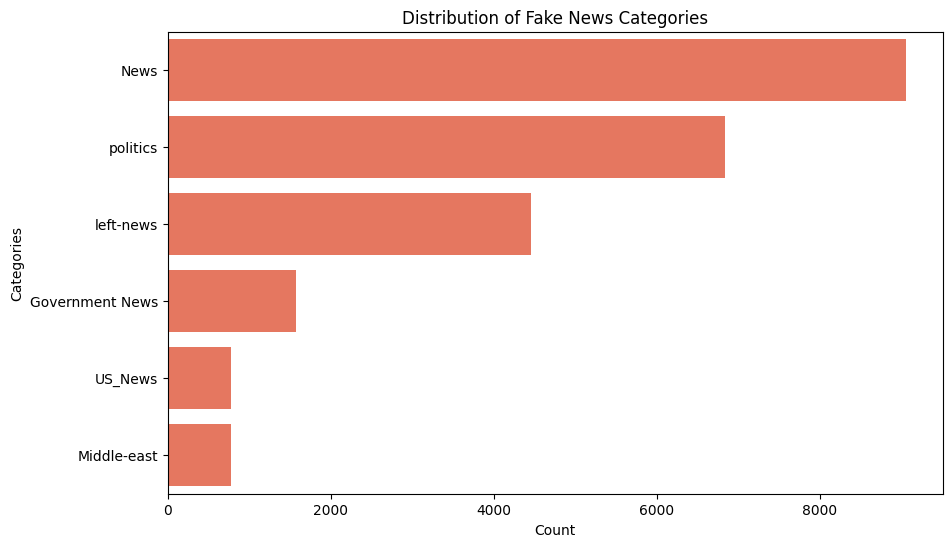

In [ ]:
print(f"--- NEWS DISTRIBUTION ---")
plt.figure(figsize=(6, 4))
sns.countplot(x="label", data=new_df, palette="viridis", hue="label", legend=False)
plt.title("Distribution of Types of News")
plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

# Distribution of real news categories
plt.figure(figsize=(10, 6))
sns.countplot(y="subject", data=new_df[new_df["label"] == "True"], order=new_df[new_df["label"] == "True"]["subject"].value_counts().index, palette="Blues", hue="label", legend=False)
plt.title("Distribution of Real News Categories")
plt.xlabel("Count")
plt.ylabel("Category")
plt.show()

# Distribution of fake news categories
plt.figure(figsize=(10, 6))
sns.countplot(y="subject", data=new_df[new_df["label"] == "Fake"], order=new_df[new_df["label"] == "Fake"]["subject"].value_counts().index, palette="Reds", hue="label", legend=False)
plt.title("Distribution of Fake News Categories")
plt.xlabel("Count")
plt.ylabel("Categories")
plt.show()



In [ ]:
print(f"--- ANALYSIS OF PATTERNS IN HEADLINES ---")
# Headline length.
new_df["title_len"] = new_df["title"].str.len()

# Presence of exclamation marks.
new_df["with_exclamation"] = new_df["title"].str.contains("!").astype(int)

# Find headlines that contain words with uppercase letters (at least 2 consecutive uppercase letters).
has_caps = lambda s: int(len(re.findall(r"\b[A-Z]{2,}\b", str(s))) > 0)
new_df["uppercase_words"] = new_df["title"].apply(has_caps)

# Calculate the mean.
analysis_headlines = new_df.groupby("label")[["title_len", "with_exclamation", "uppercase_words"]].mean()
print(f"\n {analysis_headlines}")

--- ANALYSIS OF PATTERNS IN HEADLINES ---

        title_len  with_exclamation  uppercase_words
label                                              
Fake   94.198032          0.139347         0.847920
True   64.667881          0.000840         0.161601


In [ ]:
# Remove duplicates.
new_df = new_df.drop_duplicates(subset=["text"])

In [ ]:
# Many headlines in the "True.csv" file begin with a fixed string indicating the news source and location, for example WASHINGTON (Reuters).
# Clean the text of real news by removing the source attribution prefix
headlines_true = new_df["label"] == "True"
new_df.loc[headlines_true, "text"] = new_df.loc[headlines_true, "text"].str.replace(r"^.*?\(Reuters\)\s*-\s*", "", regex=True)

# Do the same with the "Fake.csv" file.
headlines_fake = new_df["label"] == "Fake"
new_df.loc[headlines_fake, "text"] = new_df.loc[headlines_fake, "text"].str.replace(r"^.*?\(Reuters\)\s*-\s*", "", regex=True)

In [ ]:
# Text preprocessing.
nltk.download("stopwords", quiet=True) # Download NLTK stopwords
english_stopwords = set(stopwords.words("english")) # Creating a set of English stopwords

# Load the spaCy English model
nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner"]
)

def data_cleaner(text):
    text = text.lower() # Lowercase
    text = re.sub(r"\d+", "", text) # Number removal.
    text = text.translate(str.maketrans("", "", string.punctuation)) # Remove the punctuation.

    doc = nlp(text)

# Lemmatization.
# Stopword removal and text tokenization.
    return " ".join(
        token.lemma_
        for token in doc
        if token.lemma_ not in english_stopwords
    )

new_df["text"] = new_df["text"].apply(data_cleaner)

In [ ]:
# Splitting the data into training and test sets.
x = new_df["text"]
y = new_df["label"]

# "stratify=y" ensures the train and test sets have the exact same proportion of True and Fake news as the original dataset.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print("--- Training and Test Set Division ---")
print(f"Total dataset: {len(new_df)}")
print(f"Training Set (80%): {len(x_train)}")
print(f"Test Set (20%): {len(x_test)}")

--- Training and Test Set Division ---
Total dataset: 38646
Training Set (80%): 30916
Test Set (20%): 7730


In [ ]:
# Text Vectorization with TF-IDF

# Create the TF-IDF vectorizer with the vocabulary limited to the 5,000 most important terms.
vectorizer = TfidfVectorizer(max_features=5000)

# Use ".fit_transform()" on the training set to learn the vocabulary and convert the text into numerical features.
x_train_vec = vectorizer.fit_transform(x_train)

# Use ".transform()" on the test set to convert the text using only the vocabulary learned from the training set.
x_test_vec = vectorizer.transform(x_test)


In [ ]:
# Model training.
text_classifier = LogisticRegression(max_iter=1000)
text_classifier.fit(x_train_vec, y_train)

# Use the trained model to generate predictions on the unseen Set Test.
y_pred = text_classifier.predict(x_test_vec)

In [ ]:
# Accuracy Calculation.
accuracy = accuracy_score(y_test, y_pred)
print(accuracy)

0.9764553686934023


In [ ]:
# Classification Report.
print(classification_report(y_test, y_pred, target_names=["Fake", "True"]))

              precision    recall  f1-score   support

        Fake       0.98      0.97      0.97      3491
        True       0.97      0.99      0.98      4239

    accuracy                           0.98      7730
   macro avg       0.98      0.98      0.98      7730
weighted avg       0.98      0.98      0.98      7730




Real fake news correctly identified (True Negatives): 3372
Fake news incorrectly classified as real news (False Positives): 119
Real news incorrectly classified as fake news (False Negatives): 63
Real news correctly classified as real news (True Positives): 4176


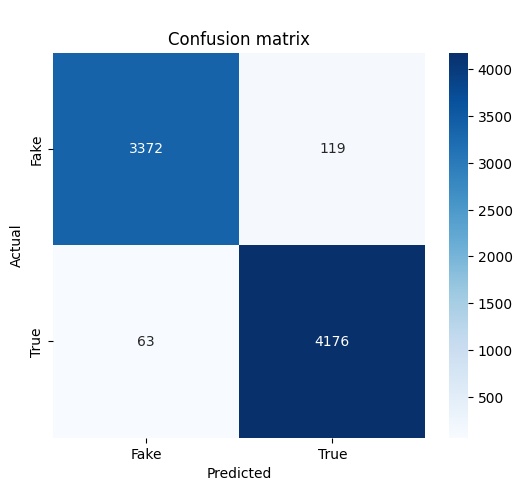

In [ ]:
# Confusion Matrix.
cm = confusion_matrix(y_test, y_pred, labels=["Fake", "True"])

print(f"\nReal fake news correctly identified (True Negatives): {cm[0][0]}")
print(f"Fake news incorrectly classified as real news (False Positives): {cm[0][1]}")
print(f"Real news incorrectly classified as fake news (False Negatives): {cm[1][0]}")
print(f"Real news correctly classified as real news (True Positives): {cm[1][1]}")

# Visual representation of the confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake","True"],
    yticklabels=["Fake","True"]
)
plt.title("\nConfusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Exporting model components in pickle format.
import pickle

# Saving the TF-IDF Vectorizer.
with open("tfidf_vectorizer.pkl", "wb") as vocab_file:
    pickle.dump(vectorizer, vocab_file)

with open("fake_news_classifier.pkl", "wb") as model_file:
    pickle.dump(text_classifier, model_file)